# Machine Learning vs Deep Learning: a hands-on comparison

Companion notebook for the article *Machine Learning vs Deep Learning* (Track 01, Module 1.1).

**What you'll learn**

1. Why a classic ML model given only the raw inputs struggles on curved (non-linear) data.
2. How a human can fix that with **hand-crafted features** (feature engineering).
3. How a small **neural network** learns useful features by itself, which is the core idea of deep learning.
4. The trade-offs: accuracy, training time, number of learned parameters, and how easy each model is to explain.

Everything runs locally in a few seconds. No GPU and no API keys are needed.
All the code is in this one notebook: run the cells from top to bottom.

## 1. Imports

We use scikit-learn for every model, including the neural network (`MLPClassifier`).
A real deep-learning project would use a framework such as PyTorch, TensorFlow or JAX, but scikit-learn's small network is enough to show the idea.

`SEED = 42` is used for every random step, so you get the same data, the same split and the same accuracies every time you run the notebook.

In [1]:
import time
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

SEED = 42
print("Random seed:", SEED)

Random seed: 42


## 2. The data: two interleaving moons

`make_moons` creates 2-D points in two classes shaped like crescent moons. Each point has just two **features**: its `x` and `y` position.
The two classes curl into each other, so **no straight line can separate them**. That makes this a good, tiny test of non-linear learning.

`load_moons` makes the data and splits it: 75 % for training, 25 % kept aside for testing. `random_state=seed` makes the data and split identical on every run, and `stratify=y` keeps the two classes balanced in both parts. A small `Dataset` box keeps the four arrays together.

In [2]:
@dataclass(frozen=True)
class Dataset:
    """Train and test splits of a 2-D classification dataset."""
    X_train: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_test: np.ndarray


def load_moons(n_samples: int = 600, noise: float = 0.25, seed: int = SEED) -> Dataset:
    """Make the two-moons dataset and split it 75 % train / 25 % test."""
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=seed)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=seed, stratify=y
    )
    return Dataset(X_train, X_test, y_train, y_test)

In [3]:
data = load_moons()
print("training points:", data.X_train.shape)
print("test points:    ", data.X_test.shape)
print("first 3 training rows (x, y) -> label:")
for row, label in zip(data.X_train[:3], data.y_train[:3]):
    print(f"  ({row[0]:+.2f}, {row[1]:+.2f}) -> {label}")

training points: (450, 2)
test points:     (150, 2)
first 3 training rows (x, y) -> label:
  (-0.26, +1.12) -> 0
  (-1.15, +0.95) -> 0
  (+1.13, +0.72) -> 0


450 points to learn from and 150 points kept aside for the final test. The models never see the test points during training, so test accuracy tells us how well each one **generalises** to new data.

**Quick check.** An `assert` line does nothing when its condition is true and stops with an error when it is false. These confirm the split sizes and that the fixed seed really gives the same data twice.

In [4]:
assert data.X_train.shape == (450, 2) and data.X_test.shape == (150, 2)
assert set(np.unique(data.y_train)) == {0, 1}                    # two classes: 0 and 1
assert np.array_equal(load_moons().X_train, data.X_train)        # same seed, same data
print("data checks passed")

data checks passed


## 3. Classic ML on the raw inputs

First, a small helper used for every model. `train_and_score` fits a model on the **training** split, times how long that takes, and measures accuracy on the **test** split. A `Result` box holds the answer.

In [5]:
@dataclass(frozen=True)
class Result:
    """How one model did: test accuracy and how long training took."""
    name: str
    accuracy: float
    train_seconds: float


def train_and_score(name: str, model: Pipeline, data: Dataset) -> Result:
    """Fit the model on the training split and score it on the test split."""
    start = time.perf_counter()
    model.fit(data.X_train, data.y_train)
    seconds = time.perf_counter() - start
    accuracy = float(model.score(data.X_test, data.y_test))
    return Result(name=name, accuracy=accuracy, train_seconds=seconds)

Next, the four models we will compare. Each one is a scikit-learn **pipeline**: the input steps (scaling, extra features) and the model are kept together, so training and prediction always apply the same steps.

- The first two are **the same algorithm** (logistic regression). Only the input features differ.
- `PolynomialFeatures(degree=3)` is our "human expert": it adds `x^2`, `x y`, `y^3`, ... columns.
- The decision tree is another classic model.
- `MLPClassifier(hidden_layer_sizes=(16, 16))` is a small neural network with two hidden layers of 16 units. It only gets scaled `x` and `y`.
- `StandardScaler` rescales inputs to mean 0 and standard deviation 1. Neural networks are sensitive to feature scale.

In [6]:
def build_models(seed: int = SEED) -> dict[str, Pipeline]:
    """Return the four (untrained) models we compare, keyed by a readable name."""
    return {
        "logistic regression (raw x, y)": make_pipeline(
            StandardScaler(), LogisticRegression()
        ),
        "logistic regression + engineered features": make_pipeline(
            PolynomialFeatures(degree=3, include_bias=False),  # hand-crafted features
            StandardScaler(),
            LogisticRegression(max_iter=1000),
        ),
        "decision tree": make_pipeline(
            DecisionTreeClassifier(max_depth=5, random_state=seed)
        ),
        "neural network (MLP)": make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=2000, random_state=seed),
        ),
    }


models = build_models()
print(len(models), "models:", list(models))

4 models: ['logistic regression (raw x, y)', 'logistic regression + engineered features', 'decision tree', 'neural network (MLP)']


Logistic regression is a classic machine-learning model. With two inputs it learns three numbers (one weight per input plus a bias) and separates the classes with a **straight line**. Let's train it on the raw `x` and `y`.

In [7]:
raw = train_and_score("logistic regression (raw x, y)", models["logistic regression (raw x, y)"], data)
print(f"{raw.name}: {raw.accuracy:.1%} test accuracy")

logistic regression (raw x, y): 86.0% test accuracy


Not bad, but a straight line cannot follow the curves, so points near the tips of the moons end up on the wrong side. The model is too simple for the shape of the data.

## 4. Classic ML with hand-crafted features

The traditional fix is **feature engineering**: a human thinks about the problem and adds new input columns that make it easier.
Here we add powers and products of `x` and `y` (`x^2`, `x y`, `y^3`, ...). With these extra columns, a straight line in the bigger feature space becomes a curve in the original 2-D picture.

In [8]:
poly = PolynomialFeatures(degree=3, include_bias=False).fit(data.X_train)
names = list(poly.get_feature_names_out(["x", "y"]))
print("2 raw features become", len(names), "engineered features:")
print(names)

2 raw features become 9 engineered features:
['x', 'y', 'x^2', 'x y', 'y^2', 'x^3', 'x^2 y', 'x y^2', 'y^3']


In [9]:
engineered = train_and_score(
    "logistic regression + engineered features",
    models["logistic regression + engineered features"],
    data,
)
tree = train_and_score("decision tree", models["decision tree"], data)
for r in (engineered, tree):
    print(f"{r.name}: {r.accuracy:.1%}")

logistic regression + engineered features: 92.0%
decision tree: 92.7%


The same logistic regression model does clearly better once a person hands it better features. That is the classic-ML workflow: **the human designs the features, the algorithm learns the weights.**

The decision tree is another classic model. It does not need polynomial features because it cuts the plane into rectangles, which can roughly follow the curves.

In [10]:
# Quick check: hand-made features helped the same algorithm.
assert engineered.accuracy > raw.accuracy

## 5. A small neural network learns its own features

`MLPClassifier` is a multi-layer perceptron: a neural network with two **hidden layers** of 16 units each.
We give it only the raw `x` and `y`. Each hidden layer combines the previous layer's outputs into new signals. Those signals are **learned features**: nobody wrote them by hand. Stacking many such layers is what the "deep" in deep learning means.

In [11]:
nn = train_and_score("neural network (MLP)", models["neural network (MLP)"], data)
mlp = models["neural network (MLP)"][-1]
print(f"{nn.name}: {nn.accuracy:.1%}")
print("layers: 2 inputs ->", " -> ".join(str(s) for s in mlp.hidden_layer_sizes), "-> 1 output")
print("training iterations:", mlp.n_iter_)

neural network (MLP): 94.7%
layers: 2 inputs -> 16 -> 16 -> 1 output
training iterations: 374


From the raw inputs alone, the network reaches the best accuracy of the four models. It found the curved shape without any feature engineering from us.

In [12]:
# Quick check: with no hand-made features, the network still beats the straight line.
assert nn.accuracy > raw.accuracy and nn.accuracy >= 0.9

## 6. Side-by-side comparison

Two more small helpers:

- `format_results` prints the results as a neat text table.
- `count_parameters` counts the **learned numbers** (weights and biases) inside a trained model. For the decision tree there are no weights, so it counts the tree's nodes instead.

In [13]:
def format_results(results: list[Result]) -> str:
    """Render results as a small fixed-width text table."""
    width = max(len(r.name) for r in results)
    lines = [f"{'model':<{width}}  accuracy  train time"]
    for r in results:
        lines.append(f"{r.name:<{width}}  {r.accuracy:>7.1%}  {r.train_seconds * 1000:>7.1f} ms")
    return "\n".join(lines)


def count_parameters(model: Pipeline) -> int:
    """Count the learned numbers in a trained model (node count for a tree)."""
    final = model[-1]  # the last step of the pipeline is the model itself
    if hasattr(final, "coefs_"):  # MLPClassifier: one weight matrix + one bias vector per layer
        return int(sum(w.size for w in final.coefs_) + sum(b.size for b in final.intercepts_))
    if hasattr(final, "coef_"):  # LogisticRegression: one weight per feature + a bias
        return int(final.coef_.size + final.intercept_.size)
    if hasattr(final, "tree_"):  # DecisionTreeClassifier
        return int(final.tree_.node_count)
    raise TypeError(f"Don't know how to count parameters of {type(final).__name__}")

Now the full table. **Training times change from run to run and machine to machine**, so compare their relative sizes, not the exact milliseconds.

In [14]:
results = [raw, engineered, tree, nn]
print(format_results(results))
print()
for name, model in models.items():
    print(f"{name:<42} learned numbers: {count_parameters(model)}")
print("(for the tree, the count is the number of nodes)")

model                                      accuracy  train time
logistic regression (raw x, y)               86.0%      3.1 ms
logistic regression + engineered features    92.0%      4.7 ms
decision tree                                92.7%      1.1 ms
neural network (MLP)                         94.7%    225.4 ms

logistic regression (raw x, y)             learned numbers: 3
logistic regression + engineered features  learned numbers: 10
decision tree                              learned numbers: 27
neural network (MLP)                       learned numbers: 337
(for the tree, the count is the number of nodes)


How to read it:

- **Accuracy:** the network wins on this curved data, and feature engineering closes much of the gap for logistic regression.
- **Training time:** the network is far slower than the classic models, even on 450 points. On real deep-learning problems this gap becomes hours or days on GPUs.
- **Learned numbers:** the network has about a hundred times more parameters than plain logistic regression. More parameters mean more flexibility, but also more data and compute to train them, and they are harder to explain.

**Quick check.** Where does 337 come from? Each layer has a weight for every input-output pair plus one bias per output unit.

In [15]:
# 2 inputs -> 16 -> 16 -> 1 output
assert count_parameters(models["neural network (MLP)"]) == (2*16 + 16) + (16*16 + 16) + (16*1 + 1) == 337
assert count_parameters(models["logistic regression (raw x, y)"]) == 2 + 1  # weights for x and y, plus a bias
print("parameter checks passed")

parameter checks passed


## 7. Seeing the decision boundaries

`plot_decision_boundary` asks a trained model to predict the class of every point on a fine grid, then shades the grid by the answer. The dots are the test points.

In [16]:
def plot_decision_boundary(ax, model: Pipeline, data: Dataset, title: str, steps: int = 200) -> None:
    """Shade the regions a trained model assigns to each class and plot the test points."""
    X = np.vstack([data.X_train, data.X_test])
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(data.X_test[:, 0], data.X_test[:, 1], c=data.y_test, cmap="coolwarm",
               edgecolors="k", s=18)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

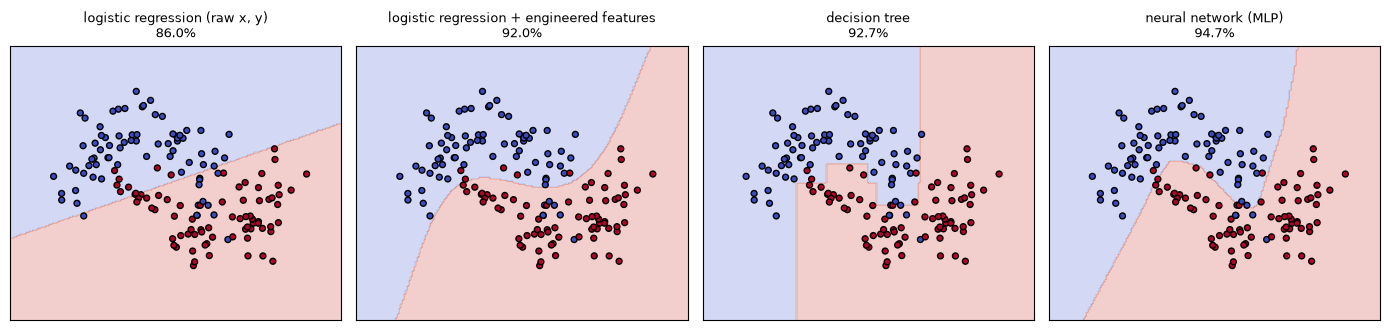

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, model), r in zip(axes, models.items(), results):
    plot_decision_boundary(ax, model, data, f"{name}\n{r.accuracy:.1%}")
fig.tight_layout()
plt.show()

- Plain logistic regression draws a straight line.
- With engineered features, the line bends into a curve.
- The decision tree makes a staircase of rectangles.
- The neural network bends its boundary to follow the moons, learned from raw `x` and `y` only. (Its boundary is made of many short straight pieces because its hidden units use the ReLU activation, which is scikit-learn's default.)

## 8. Interpretability: which model can you explain?

A classic model is often easy to inspect. Logistic regression has one weight per feature, and a shallow tree can be printed as plain if/else rules.

In [18]:
lr = models["logistic regression (raw x, y)"][-1]
print("logistic regression weights (x, y):", lr.coef_.round(2), " bias:", lr.intercept_.round(2))
print()
print("decision tree, top two levels of rules:")
print(export_text(models["decision tree"][-1], feature_names=["x", "y"], max_depth=1))

logistic regression weights (x, y): [[ 1.13 -2.16]]  bias: [-0.03]

decision tree, top two levels of rules:
|--- y <= 0.25
|   |--- x <= -0.56
|   |   |--- class: 0
|   |--- x >  -0.56
|   |   |--- truncated branch of depth 4
|--- y >  0.25
|   |--- x <= 1.31
|   |   |--- truncated branch of depth 4
|   |--- x >  1.31
|   |   |--- class: 1



You can read these and say *why* a point got its label. The network's 337 numbers have no such simple reading, because each hidden unit mixes all of its inputs. That is the usual trade: **deep learning gives flexibility on complex data; classic ML gives speed and explainability.**

## 9. How much data does each model need?

Deep learning is known for needing lots of data. Let's train the engineered logistic regression and the network on smaller slices of the training set and test both on the same 150 test points.

In [19]:
for n in (20, 50, 450):
    small = Dataset(data.X_train[:n], data.X_test, data.y_train[:n], data.y_test)
    fresh = build_models()
    lr_r, nn_r = (train_and_score(k, fresh[k], small) for k in
                  ("logistic regression + engineered features", "neural network (MLP)"))
    print(f"{n:>3} training points:  engineered LR {lr_r.accuracy:.1%}   neural net {nn_r.accuracy:.1%}")

 20 training points:  engineered LR 84.7%   neural net 86.0%


 50 training points:  engineered LR 88.7%   neural net 89.3%


450 training points:  engineered LR 92.0%   neural net 94.7%


On this tiny 2-D problem both models stay close when data is scarce, and the network's lead grows as it gets more examples: with all 450 points it pulls ahead. Two lessons:

- **More data helps the more flexible model more.** The network has many more parameters to tune, and extra examples are what let it use that flexibility.
- **The "deep learning needs huge data" rule is about big networks on hard problems** such as images or language, where models have millions or billions of parameters. Our 337-parameter network on a 2-D toy is small enough to cope with little data. Exact numbers will differ if you change the seed or the slice of data, so treat this as a sketch, not a law.

## 10. Recap

- **AI contains machine learning, which contains deep learning.** Every model here is machine learning; only the neural network is (a tiny) deep-learning model.
- **Classic ML** works on features a human chooses. With good features it is fast, accurate and easy to explain.
- **Deep learning** stacks layers that **learn their own features** from raw input. It shines on complex data such as images, audio and text, but costs more data, compute and interpretability.
- **Pick classic ML** for small, tabular, well-understood problems or when you must explain decisions. **Pick deep learning** for raw, unstructured data at scale.
- Large language models are deep-learning models with billions of parameters, so everything in the coming lessons builds on these ideas.

**Try next:** change `noise` in `load_moons(noise=...)` (section 2), change `hidden_layer_sizes` in `build_models` (section 3), or swap in `sklearn.datasets.load_digits` (8x8 images of handwritten digits). If you change the data or the models, some quick-check `assert` lines may fail: that is expected, they were written for the default settings.